# Chapter 1: Four boxes that tell the truth: where did each customer land?

*The confusion matrix, cell by cell · also searched as: confusion matrix explained, true positive false positive*

**Who needs the answer.** Kavya Nair, Kalpa Retail's senior analyst, who will not read a model score until she has seen its four boxes, and Anand Iyer in Finance, who prices two of those boxes in rupees.

**The questions on the way.** Into which box does each customer fall? What does each box mean in Kalpa's words? Which two boxes cost money, and how much? How does scikit-learn lay the boxes out?

You will be able to sort any small table into the four boxes by hand, read each box aloud as a business sentence, and check your count against scikit-learn.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

import pandas as pd, numpy as np
# Invented: twenty Kalpa Retail customers, whether the model said "nudge", and whether they came back within ninety days.
kalpa = pd.DataFrame({
    "customer": [f"C{i:02d}" for i in range(1, 21)],
    "model_says_nudge": [0,1,0,0,1,0,1,0,0,0,1,0,0,1,0,1,0,0,0,0],
    "came_back":        [0,1,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0],
})
print(kalpa.to_string(index=False))

customer  model_says_nudge  came_back
     C01                 0          0
     C02                 1          1
     C03                 0          0
     C04                 0          0
     C05                 1          1
     C06                 0          0
     C07                 1          0
     C08                 0          0
     C09                 0          1
     C10                 0          0
     C11                 1          0
     C12                 0          0
     C13                 0          0
     C14                 1          1
     C15                 0          0
     C16                 1          0
     C17                 0          0
     C18                 0          1
     C19                 0          0
     C20                 0          0


## Where does each customer land?

Every customer gets two labels: what the model said (nudge or leave) and what happened (came back or not). Two labels with two values each make four boxes.

**Predict before you run.** How many customers sit in the box "the model said nudge and they came back"? (a) 1, (b) 3, (c) 5, (d) 6.

In [2]:
boxes = {"TP": [], "FP": [], "FN": [], "TN": []}
for _, row in kalpa.iterrows():
    if row.model_says_nudge == 1 and row.came_back == 1:   boxes["TP"].append(row.customer)
    elif row.model_says_nudge == 1 and row.came_back == 0: boxes["FP"].append(row.customer)
    elif row.model_says_nudge == 0 and row.came_back == 1: boxes["FN"].append(row.customer)
    else:                                                  boxes["TN"].append(row.customer)
meaning = {"TP": "nudged and came back", "FP": "nudged, did not come back", "FN": "left alone, came back anyway or was lost", "TN": "left alone, did not come back"}
for k, v in boxes.items():
    print(f"{k}  {len(v):>2}  {meaning[k]:<42} {' '.join(v)}")

TP   3  nudged and came back                       C02 C05 C14
FP   3  nudged, did not come back                  C07 C11 C16
FN   2  left alone, came back anyway or was lost   C09 C18
TN  12  left alone, did not come back              C01 C03 C04 C06 C08 C10 C12 C13 C15 C17 C19 C20


**What happened.** The answer is (b): C02, C05 and C14 were nudged and came back. The model flagged six customers, so the other three flags (C07, C11, C16) are false alarms, and two real repeaters (C09, C18) were never nudged. Twelve customers were correctly left alone.

## What do the four boxes look like?

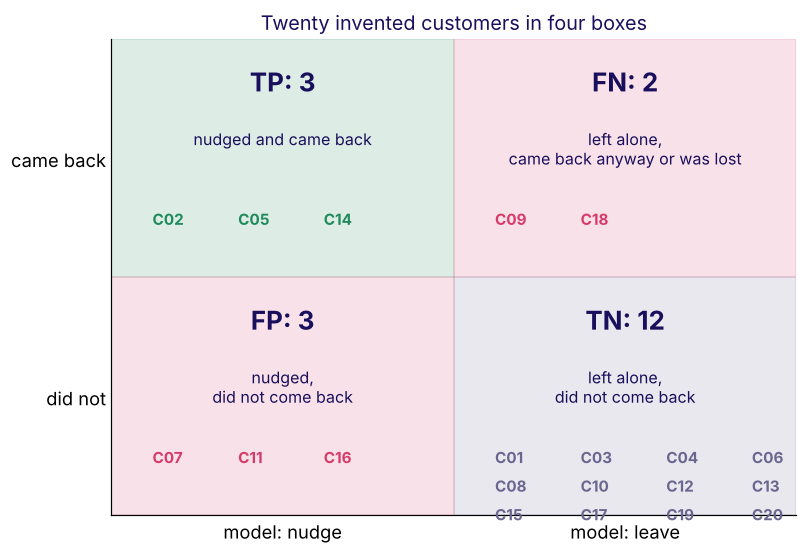

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
layout = {"TP": (0, 1, GREEN), "FN": (1, 1, ROSE), "FP": (0, 0, ROSE), "TN": (1, 0, MUTED)}
for k, (x, y, col) in layout.items():
    ax.add_patch(plt.Rectangle((x, y), 1, 1, color=col, alpha=0.15))
    ax.text(x + 0.5, y + 0.78, f"{k}: {len(boxes[k])}", ha="center", fontsize=17, weight="bold", color=INK)
    ax.text(x + 0.5, y + 0.62, meaning[k].replace(", ", ",\n"), ha="center", va="top", fontsize=10.5, color=INK)
    for i, c in enumerate(boxes[k]):
        ax.text(x + 0.12 + (i % 4) * 0.25, y + 0.22 - (i // 4) * 0.12, c, fontsize=10, color=col, weight="bold")
ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_xticks([0.5, 1.5]); ax.set_xticklabels(["model: nudge", "model: leave"])
ax.set_yticks([1.5, 0.5]); ax.set_yticklabels(["came back", "did not"]); ax.tick_params(length=0)
ax.set_title("Twenty invented customers in four boxes", color=INK); plt.tight_layout(); plt.show()

## Which boxes cost Kalpa money?

Two boxes are right and cost nothing extra. Two are mistakes, and Anand prices them differently: a wasted nudge (FP) costs Rs 40, and a repeater left alone (FN) costs about Rs 1,200 of margin.

In [4]:
COST_FP, COST_FN = 40, 1200
tp, fp, fn, tn = (len(boxes[k]) for k in ("TP", "FP", "FN", "TN"))
print(f"wasted nudges: {fp} x Rs {COST_FP} = Rs {fp * COST_FP:,}")
print(f"missed repeaters: {fn} x Rs {COST_FN:,} = Rs {fn * COST_FN:,}")
print(f"the bill of mistakes: Rs {fp * COST_FP + fn * COST_FN:,}")
print("PASS  the four boxes hold all twenty customers" if tp + fp + fn + tn == 20 else "CHECK box total")
print("PASS  flagged = TP + FP = 6" if tp + fp == kalpa.model_says_nudge.sum() == 6 else "CHECK flagged")

wasted nudges: 3 x Rs 40 = Rs 120
missed repeaters: 2 x Rs 1,200 = Rs 2,400
the bill of mistakes: Rs 2,520
PASS  the four boxes hold all twenty customers
PASS  flagged = TP + FP = 6


## The trap: which number is the true positives in scikit-learn's printout?

`confusion_matrix(truth, prediction)` prints rows for the truth and columns for the prediction, sorted 0 then 1, so its top-left cell is the **true negatives**. A hurried reader sees `[[12, 3], [2, 3]]` and reports "12 true positives", which would tell Marketing the model found twelve repeaters when it found three. The check: the bottom row must add up to the number of real repeaters, five. The fix: always print the matrix with its labels.

In [5]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(kalpa.came_back, kalpa.model_says_nudge)
print(cm)
labelled = pd.DataFrame(cm, index=["truth: did not", "truth: came back"], columns=["model: leave", "model: nudge"])
print(labelled)
print("PASS  scikit-learn's bottom-right cell is our TP" if cm[1, 1] == tp else "CHECK TP")
print("PASS  the bottom row sums to the five real repeaters" if cm[1].sum() == kalpa.came_back.sum() == 5 else "CHECK row sum")

[[12  3]
 [ 2  3]]
                  model: leave  model: nudge
truth: did not              12             3
truth: came back             2             3
PASS  scikit-learn's bottom-right cell is our TP
PASS  the bottom row sums to the five real repeaters


## What did this chapter establish?

| Box | Kalpa's words | Count | Cost each |
|---|---|---|---|
| TP | nudged and came back | 3 | none |
| FP | nudged, did not come back | 3 | Rs 40 |
| FN | left alone, a repeater missed | 2 | Rs 1,200 |
| TN | left alone, did not come back | 12 | none |

**The rule.** The confusion matrix is the count of each pair (what the model said, what happened); every metric of the day is a ratio of its four cells. It flips meaning when someone swaps rows and columns, so a matrix without labels is unread.

**In the interview.** "Read this matrix aloud in the business's words." Name each cell as a customer outcome and price the two mistakes.

Chapter 2 turns the four counts into precision, recall and F1.